# Publication figures

Five figures for the report, drawn only from `results/artifacts`. Nothing is retrained.

Run the cells from top to bottom. PNG and PDF copies are written to `results/artifacts/figures_pub/`.


In [1]:
%matplotlib inline

import csv
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from matplotlib import font_manager
from matplotlib.gridspec import GridSpec

def find_artifacts():
    here = Path.cwd().resolve()
    candidates = []
    for root in [here, *here.parents]:
        candidates.append(root / "results" / "artifacts")
        candidates.append(root / "artifacts")
        if len(candidates) > 12:
            break
    for path in candidates:
        if (path / "metrics.csv").exists() and (path / "test8.pt").exists():
            return path
    raise FileNotFoundError("Could not find results/artifacts. Open the notebook from the project folder.")

ART = find_artifacts()
OUT = ART / "figures_pub"
OUT.mkdir(parents=True, exist_ok=True)

available = {font.name for font in font_manager.fontManager.ttflist}
for family in ("Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"):
    if family in available:
        plt.rcParams["font.family"] = family
        break

plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 9,
    "axes.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "legend.fontsize": 7.5,
    "legend.frameon": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.unicode_minus": False,
})

INK = "#1c1c1c"
MUTED = "#5c5c5c"
HAIR = "#c8c8c8"
COLORS = {
    "Vanilla AE": "#0072B2",
    "Sparse AE": "#E69F00",
    "VAE": "#009E73",
    "Generator": "#D55E00",
    "Discriminator": "#0072B2",
    "DDPM": "#CC79A7",
}

def load_tensor(name, filename):
    payload = torch.load(ART / name / filename, map_location="cpu", weights_only=False)
    if isinstance(payload, dict) and "images" in payload:
        return payload
    return payload

def as_images(payload):
    if isinstance(payload, dict):
        return payload["images"]
    return payload

def paint(ax, image):
    array = image[0].detach().float().cpu()
    ax.imshow(array, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(HAIR)
        spine.set_linewidth(0.4)

def save(fig, stem):
    fig.savefig(OUT / f"{stem}.png", dpi=300, bbox_inches="tight", pad_inches=0.04)
    fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight", pad_inches=0.04)
    plt.show()

test8 = torch.load(ART / "test8.pt", map_location="cpu", weights_only=False)
originals = test8["images"]
print("artifacts", ART)


artifacts C:\Users\Alif Akbar Hafiz\Desktop\Perbinusan\5th Semester\1_DeepLearning\2_Assignment\results\artifacts


## Figure 1. Reconstruction

Same eight test images. Vanilla AE keeps edges. The sparse penalty softens them only slightly. The VAE, trained with a KL term, averages each garment into a blur.


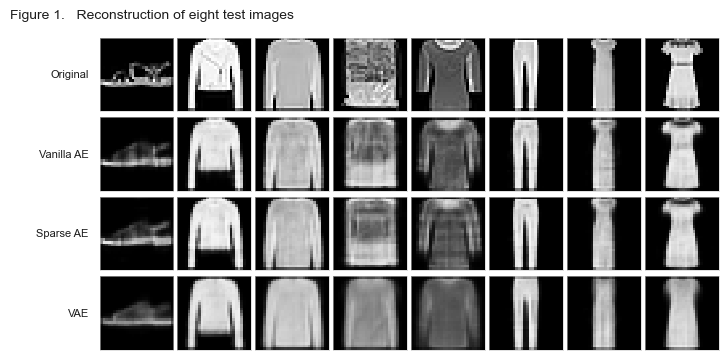

In [2]:
rows = [
    ("Original", originals),
    ("Vanilla AE", as_images(load_tensor("vanilla_ae", "recon.pt"))),
    ("Sparse AE", as_images(load_tensor("sparse_ae", "recon.pt"))),
    ("VAE", as_images(load_tensor("vae", "recon.pt"))),
]
fig = plt.figure(figsize=(7.2, 3.55))
grid = GridSpec(
    4, 9, figure=fig,
    width_ratios=[1.15] + [1] * 8,
    wspace=0.045, hspace=0.08,
    left=0.01, right=0.995, top=0.90, bottom=0.02,
)
fig.suptitle("Figure 1.   Reconstruction of eight test images", x=0.01, ha="left", fontsize=10, color=INK)
for row, (label, images) in enumerate(rows):
    axis = fig.add_subplot(grid[row, 0])
    axis.axis("off")
    axis.text(0.92, 0.5, label, ha="right", va="center", fontsize=8, color=INK)
    for col in range(8):
        paint(fig.add_subplot(grid[row, col + 1]), images[col])
save(fig, "figure1_reconstruction")


## Figure 2. Samples from the prior

Sixteen draws each. VAE samples are soft. The fully connected GAN is sharp but broken. DCGAN and DDPM keep a garment silhouette; DCGAN has the lower FID.


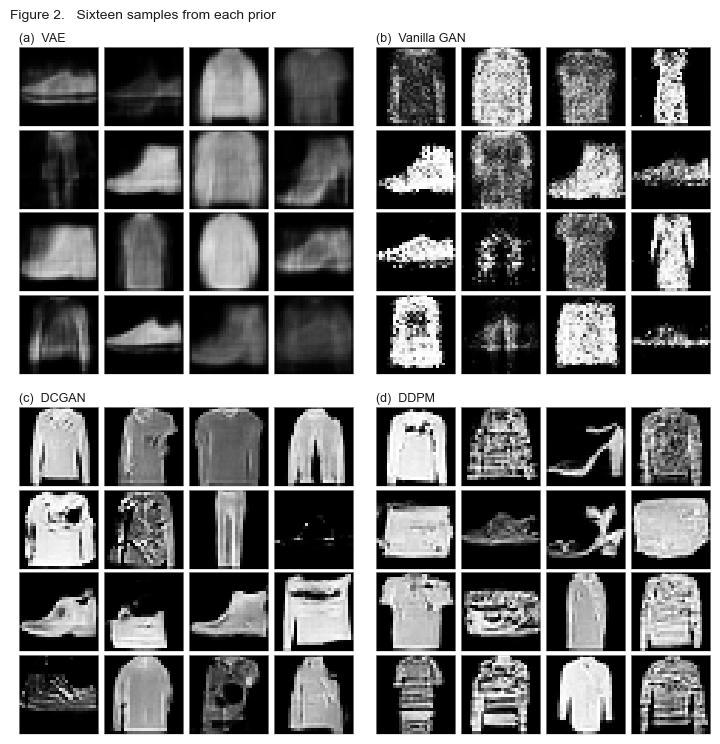

In [3]:
panels = [
    ("(a)  VAE", as_images(load_tensor("vae", "samples_grid.pt"))),
    ("(b)  Vanilla GAN", as_images(load_tensor("vanilla_gan", "samples_grid.pt"))),
    ("(c)  DCGAN", as_images(load_tensor("dcgan", "samples_grid.pt"))),
    ("(d)  DDPM", as_images(load_tensor("ddpm", "samples_grid.pt"))),
]
fig = plt.figure(figsize=(7.2, 7.55))
fig.suptitle("Figure 2.   Sixteen samples from each prior", x=0.01, ha="left", fontsize=10, color=INK)
outer = GridSpec(2, 2, figure=fig, wspace=0.06, hspace=0.10, left=0.02, right=0.985, top=0.93, bottom=0.02)
for index, (title, images) in enumerate(panels):
    inner = outer[index].subgridspec(4, 4, wspace=0.035, hspace=0.045)
    for cell in range(16):
        axis = fig.add_subplot(inner[cell])
        paint(axis, images[cell])
        if cell == 0:
            axis.set_title(title, loc="left", fontsize=9, color=INK, pad=4)
save(fig, "figure2_samples")


## Figure 3. A classifier is not a generator

The MLP reaches 89.1% test accuracy and still cannot return an image. Transposed weights are noise. A decoder fit on the frozen 64-d features is blurrier than the vanilla autoencoder. Draws from that feature cloud do not form a new garment.


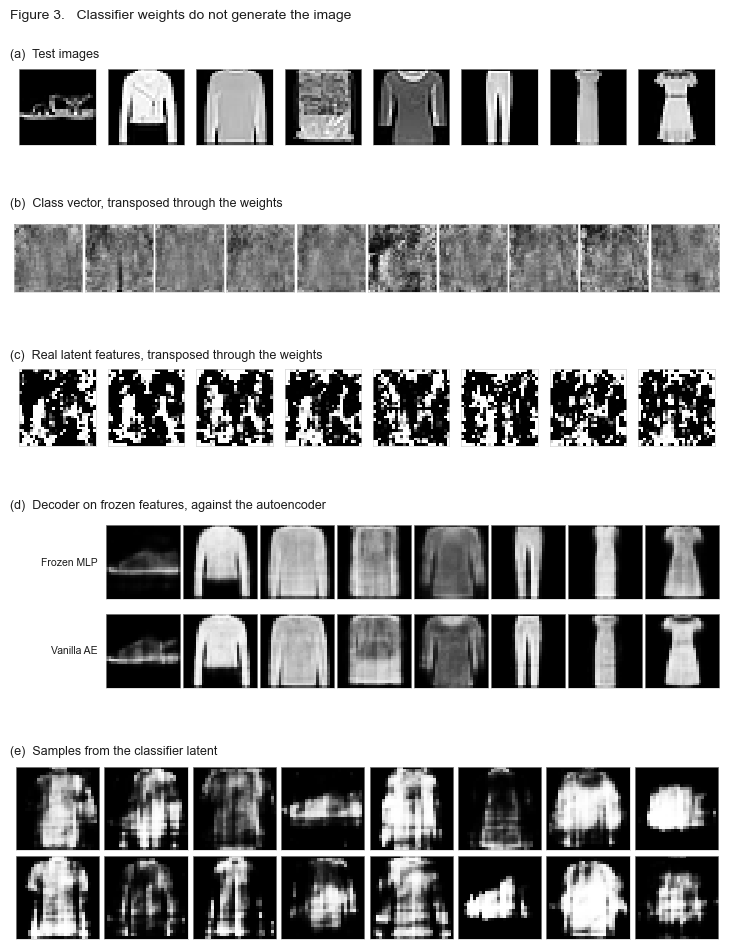

In [4]:
vanilla = as_images(load_tensor("vanilla_ae", "recon.pt"))
blocks = [
    ("(a)  Test images", [(" ", originals)]),
    ("(b)  Class vector, transposed through the weights", [(" ", as_images(load_tensor("mlp", "class_projections.pt")))]),
    ("(c)  Real latent features, transposed through the weights", [(" ", as_images(load_tensor("mlp", "latent_projections.pt")))]),
    ("(d)  Decoder on frozen features, against the autoencoder", [
        ("Frozen MLP", as_images(load_tensor("mlp", "frozen_recon.pt"))),
        ("Vanilla AE", vanilla),
    ]),
    ("(e)  Samples from the classifier latent", [(" ", as_images(load_tensor("mlp", "prior_samples.pt"))[:8]), (" ", as_images(load_tensor("mlp", "prior_samples.pt"))[8:])]),
]

fig = plt.figure(figsize=(7.2, 9.6))
fig.suptitle("Figure 3.   Classifier weights do not generate the image", x=0.01, ha="left", fontsize=10, color=INK)
section = GridSpec(5, 1, figure=fig, height_ratios=[1.22, 1.28, 1.22, 2.35, 2.35], hspace=0.28, left=0.01, right=0.995, top=0.95, bottom=0.012)

for block_index, (title, rows) in enumerate(blocks):
    ncol = max(images.shape[0] for _, images in rows)
    nrow = len(rows)
    label_width = 1.25 if any(label.strip() for label, _ in rows) else 0.02
    inner = section[block_index].subgridspec(
        nrow + 1, ncol + 1,
        height_ratios=[0.34] + [1] * nrow,
        width_ratios=[label_width] + [1] * ncol,
        wspace=0.04, hspace=0.08,
    )
    heading = fig.add_subplot(inner[0, :])
    heading.axis("off")
    heading.text(0.0, 0.15, title, ha="left", va="bottom", fontsize=9, color=INK)
    for row, (label, images) in enumerate(rows):
        axis = fig.add_subplot(inner[row + 1, 0])
        axis.axis("off")
        if label.strip():
            axis.text(0.95, 0.5, label, ha="right", va="center", fontsize=7.5, color=INK)
        for col in range(images.shape[0]):
            paint(fig.add_subplot(inner[row + 1, col + 1]), images[col])
save(fig, "figure3_mlp")


## Figure 4. Linear interpolation

`z(α) = (1 − α) z_A + α z_B`, with α from 0 to 1. Autoencoders encode a T-shirt/top and an ankle boot. The gap in the middle is a latent void. The VAE crosses the same pair without breaking the silhouette. The GAN rows walk between two fixed noise vectors, because those models have no encoder.


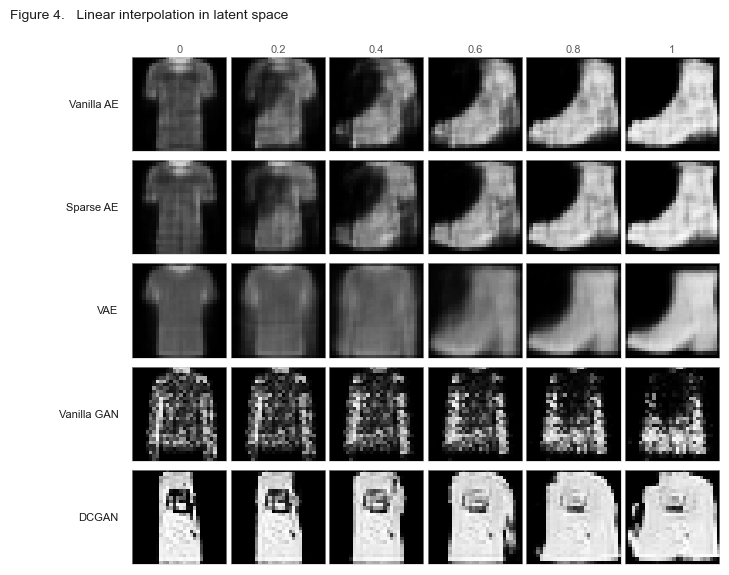

In [5]:
strips = [
    ("Vanilla AE", as_images(load_tensor("vanilla_ae", "interp.pt"))),
    ("Sparse AE", as_images(load_tensor("sparse_ae", "interp.pt"))),
    ("VAE", as_images(load_tensor("vae", "interp.pt"))),
    ("Vanilla GAN", as_images(load_tensor("vanilla_gan", "interp.pt"))),
    ("DCGAN", as_images(load_tensor("dcgan", "interp.pt"))),
]
alphas = ["0", "0.2", "0.4", "0.6", "0.8", "1"]
fig = plt.figure(figsize=(7.2, 5.85))
fig.suptitle("Figure 4.   Linear interpolation in latent space", x=0.01, ha="left", fontsize=10, color=INK)
grid = GridSpec(
    5, 7, figure=fig,
    width_ratios=[1.25] + [1] * 6,
    wspace=0.045, hspace=0.08,
    left=0.01, right=0.995, top=0.90, bottom=0.03,
)
for row, (label, images) in enumerate(strips):
    axis = fig.add_subplot(grid[row, 0])
    axis.axis("off")
    axis.text(0.92, 0.5, label, ha="right", va="center", fontsize=8, color=INK)
    for col in range(6):
        axis = fig.add_subplot(grid[row, col + 1])
        paint(axis, images[col])
        if row == 0:
            axis.set_title(alphas[col], fontsize=8, color=MUTED, pad=3)
save(fig, "figure4_interpolation")


## Figure 5. Training curves and one reverse chain

Reconstruction loss is mean pixel error. GAN panels show the generator and the discriminator separately. The strip is one DDPM chain from step 1000 to step 0.


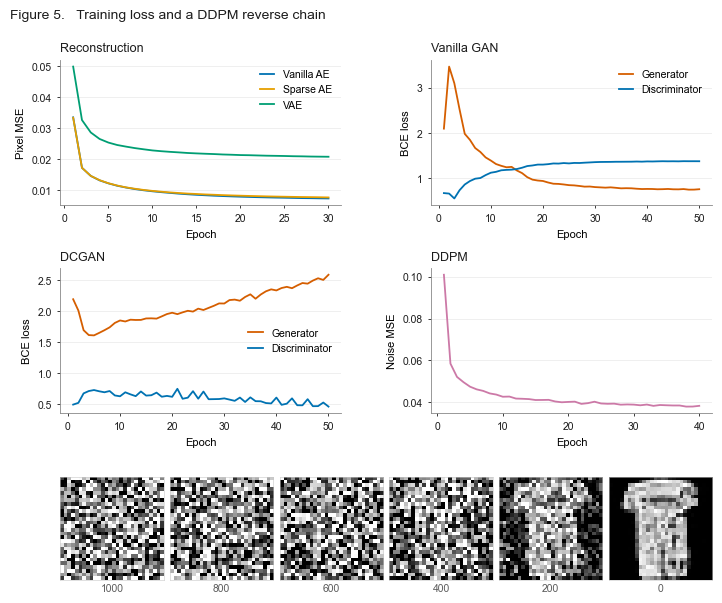

In [6]:
import json

def json_load(path):
    return json.loads(path.read_text(encoding="utf-8"))

vanilla_hist = json_load(ART / "vanilla_ae" / "history.json")
sparse_hist = json_load(ART / "sparse_ae" / "history.json")
vae_hist = json_load(ART / "vae" / "history.json")
gan_hist = json_load(ART / "vanilla_gan" / "history.json")
dcgan_hist = json_load(ART / "dcgan" / "history.json")
ddpm_hist = json_load(ART / "ddpm" / "history.json")
trajectory = load_tensor("ddpm", "trajectory.pt")

def style_axis(axis, ylabel):
    axis.set_xlabel("Epoch")
    axis.set_ylabel(ylabel)
    axis.tick_params(colors=INK)
    axis.yaxis.grid(True, linewidth=0.4, color="#e4e4e4")
    axis.set_axisbelow(True)
    for spine in ("left", "bottom"):
        axis.spines[spine].set_color("#888888")

fig = plt.figure(figsize=(7.2, 6.35))
fig.suptitle("Figure 5.   Training loss and a DDPM reverse chain", x=0.01, ha="left", fontsize=10, color=INK)
grid = GridSpec(3, 2, figure=fig, height_ratios=[1, 1, 0.72], hspace=0.48, wspace=0.32, left=0.08, right=0.985, top=0.90, bottom=0.08)

def epochs(values):
    return range(1, len(values) + 1)

axis = fig.add_subplot(grid[0, 0])
axis.plot(epochs(vanilla_hist["recon_loss"]), vanilla_hist["recon_loss"], color=COLORS["Vanilla AE"], lw=1.3, label="Vanilla AE")
axis.plot(epochs(sparse_hist["recon_loss"]), sparse_hist["recon_loss"], color=COLORS["Sparse AE"], lw=1.3, label="Sparse AE")
axis.plot(epochs(vae_hist["recon_loss"]), vae_hist["recon_loss"], color=COLORS["VAE"], lw=1.3, label="VAE")
style_axis(axis, "Pixel MSE")
axis.set_title("Reconstruction", loc="left", color=INK)
axis.legend(loc="upper right", handlelength=1.4)

axis = fig.add_subplot(grid[0, 1])
axis.plot(epochs(gan_hist["g_loss"]), gan_hist["g_loss"], color=COLORS["Generator"], lw=1.3, label="Generator")
axis.plot(epochs(gan_hist["d_loss"]), gan_hist["d_loss"], color=COLORS["Discriminator"], lw=1.3, label="Discriminator")
style_axis(axis, "BCE loss")
axis.set_title("Vanilla GAN", loc="left", color=INK)
axis.legend(loc="upper right", handlelength=1.4)

axis = fig.add_subplot(grid[1, 0])
axis.plot(epochs(dcgan_hist["g_loss"]), dcgan_hist["g_loss"], color=COLORS["Generator"], lw=1.3, label="Generator")
axis.plot(epochs(dcgan_hist["d_loss"]), dcgan_hist["d_loss"], color=COLORS["Discriminator"], lw=1.3, label="Discriminator")
style_axis(axis, "BCE loss")
axis.set_title("DCGAN", loc="left", color=INK)
axis.legend(loc="center right", handlelength=1.4)

axis = fig.add_subplot(grid[1, 1])
axis.plot(epochs(ddpm_hist["train_loss"]), ddpm_hist["train_loss"], color=COLORS["DDPM"], lw=1.3)
style_axis(axis, "Noise MSE")
axis.set_title("DDPM", loc="left", color=INK)

steps = trajectory["steps"]
frames = trajectory["images"]
strip = grid[2, :].subgridspec(1, len(steps), wspace=0.06)
for index, step in enumerate(steps):
    axis = fig.add_subplot(strip[index])
    paint(axis, frames[index])
    axis.set_xlabel(str(step), fontsize=7.5, color=MUTED, labelpad=2)
save(fig, "figure5_curves")


## Metrics table

Reconstruction scores are blank for models with no encoder. FID is blank for the autoencoders, which were not trained to sample a prior. Latency is one batch of 64 images; for DDPM that is the full reverse chain.


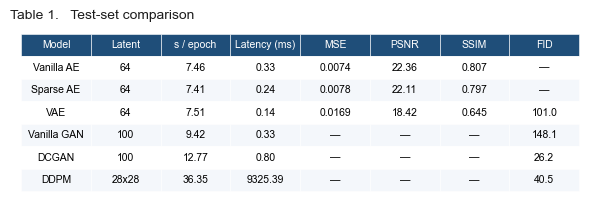

Vanilla AE  64  7.46  0.33  0.0074  22.36  0.807  —
Sparse AE  64  7.41  0.24  0.0078  22.11  0.797  —
VAE  64  7.51  0.14  0.0169  18.42  0.645  101.0
Vanilla GAN  100  9.42  0.33  —  —  —  148.1
DCGAN  100  12.77  0.80  —  —  —  26.2
DDPM  28x28  36.35  9325.39  —  —  —  40.5


In [7]:
def blank(value):
    text = "" if value is None else str(value).strip()
    return "—" if text == "" else text

def pretty(value, digits):
    text = blank(value)
    if text == "—":
        return text
    return f"{float(text):.{digits}f}"

with (ART / "metrics.csv").open(encoding="utf-8") as handle:
    source_rows = list(csv.DictReader(handle))

headers = ["Model", "Latent", "s / epoch", "Latency (ms)", "MSE", "PSNR", "SSIM", "FID"]
body = []
for row in source_rows:
    body.append([
        row["model"].replace("Autoencoder", "AE").replace("Variational AE", "VAE").replace("Generative Adversarial Network", "GAN"),
        row["latent_dim"],
        pretty(row["sec_per_epoch"], 2),
        pretty(row["latency_ms"], 2),
        pretty(row["test_mse"], 4),
        pretty(row["test_psnr"], 2),
        pretty(row["test_ssim"], 3),
        pretty(row["fid"], 1),
    ])

fig, axis = plt.subplots(figsize=(7.2, 2.15))
axis.axis("off")
axis.set_title("Table 1.   Test-set comparison", loc="left", fontsize=10, color=INK, pad=8)
table = axis.table(cellText=body, colLabels=headers, loc="upper left", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(7.5)
table.scale(1, 1.35)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("white")
    cell.set_linewidth(0.4)
    if row == 0:
        cell.set_facecolor("#1f4e79")
        cell.set_text_props(color="white", fontweight="medium")
    elif row % 2 == 0:
        cell.set_facecolor("#f4f7fb")
    else:
        cell.set_facecolor("white")
    cell.PAD = 0.08
save(fig, "table1_metrics")
for line in body:
    print("  ".join(line))
